# Tugas: Clustering dengan DBSCAN, BIRCH, dan EM (Gaussian Mixture Model)

| Nama | NRP |
|------|-----|
| Daffa Aufa Afif | 5054251022 |

## Deskripsi Tugas

Pada tugas ini, kalian akan melakukan clustering pada data pelanggan pusat perbelanjaan (*Mall Customer Segmentation*). Kalian akan membandingkan tiga pendekatan clustering:

1. **DBSCAN**, yang membentuk cluster berdasarkan kepadatan data dan dapat menandai data sebagai noise.
2. **BIRCH**, yang merangkum data ke dalam struktur pohon untuk membentuk subcluster.
3. **Expectation-Maximization (EM)** menggunakan **Gaussian Mixture Model (GMM)**, yang memodelkan data sebagai campuran beberapa distribusi probabilitas.

Dataset: [Mall Customer Segmentation Data di Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data).

Setiap baris mewakili satu pelanggan. Pada tugas ini, gunakan dua fitur agar hasilnya mudah divisualisasikan:
- `Annual Income (k$)`: pendapatan tahunan dalam ribuan dolar.
- `Spending Score (1-100)`: skor pengeluaran pelanggan.

**Penting:** `CustomerID` hanya merupakan identitas pelanggan, sehingga tidak digunakan sebagai fitur clustering. Kolom `Gender` juga tidak digunakan dalam eksperimen utama agar fokus tetap pada dua fitur numerik. Kolom tersebut boleh digunakan untuk interpretasi tambahan setelah model selesai, bukan sebagai input model.

## Tujuan Pembelajaran

- Melakukan eksplorasi dan preprocessing data sederhana.
- Memahami mengapa feature scaling diperlukan.
- Menjalankan DBSCAN, BIRCH, dan GMM dengan EM.
- Memahami parameter utama dan karakteristik setiap algoritma.
- Membandingkan hasil clustering menggunakan visualisasi dan metrik evaluasi internal.

## Persiapan Dataset

Unduh file CSV dari halaman Kaggle di atas. Letakkan file `Mall_Customers.csv` di folder yang sama dengan notebook ini. Nama file biasanya `Mall_Customers.csv`.

Langkah pengerjaan:
1. Persiapan dataset dan eksplorasi awal.
2. Preprocessing dan feature scaling.
3. Eksperimen DBSCAN.
4. Eksperimen BIRCH.
5. Eksperimen EM menggunakan Gaussian Mixture Model.
6. Evaluasi dan perbandingan model.
7. Analisis serta kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [3]:
# Import library yang dibutuhkan:
# pandas, numpy, matplotlib, seaborn
# StandardScaler dari sklearn.preprocessing
# DBSCAN dari sklearn.cluster
# Birch dari sklearn.cluster
# GaussianMixture dari sklearn.mixture
# silhouette_score, davies_bouldin_score, calinski_harabasz_score dari sklearn.metrics

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

SEED = 42
plt.rcParams['figure.figsize'] = (8, 5)


In [4]:
# Muat Mall_Customers.csv ke dalam DataFrame bernama df.
# Jika file tidak ditemukan, periksa lokasi file dan nama file.
# Tampilkan 5 baris pertama, jumlah baris/kolom, tipe data, statistik deskriptif,
# jumlah missing value, dan jumlah baris duplikat.

df = pd.read_csv('Mall_Customers.csv')
print('5 baris pertama:\n', df.head().to_string(index=False))
print('\nUkuran:', df.shape)
print('\nTipe data:\n', df.dtypes.to_string())
print('\nStatistik deskriptif:\n', df.describe(include='all').to_string())
print('\nMissing value:\n', df.isna().sum().to_string())
print('\nJumlah baris duplikat:', df.duplicated().sum())

5 baris pertama:
  CustomerID Gender  Age  Annual Income (k$)  Spending Score (1-100)
          1   Male   19                  15                      39
          2   Male   21                  15                      81
          3 Female   20                  16                       6
          4 Female   23                  16                      77
          5 Female   31                  17                      40

Ukuran: (200, 5)

Tipe data:
 CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64

Statistik deskriptif:
         CustomerID  Gender         Age  Annual Income (k$)  Spending Score (1-100)
count   200.000000     200  200.000000          200.000000              200.000000
unique         NaN       2         NaN                 NaN                     NaN
top            NaN  Female         NaN                 NaN                     NaN
freq           NaN     112 

       Annual Income (k$)  Spending Score (1-100)
count          200.000000              200.000000
mean            60.560000               50.200000
std             26.264721               25.823522
min             15.000000                1.000000
25%             41.500000               34.750000
50%             61.500000               50.000000
75%             78.000000               73.000000
max            137.000000               99.000000


<ipython-input-1-b5467e651d36>:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


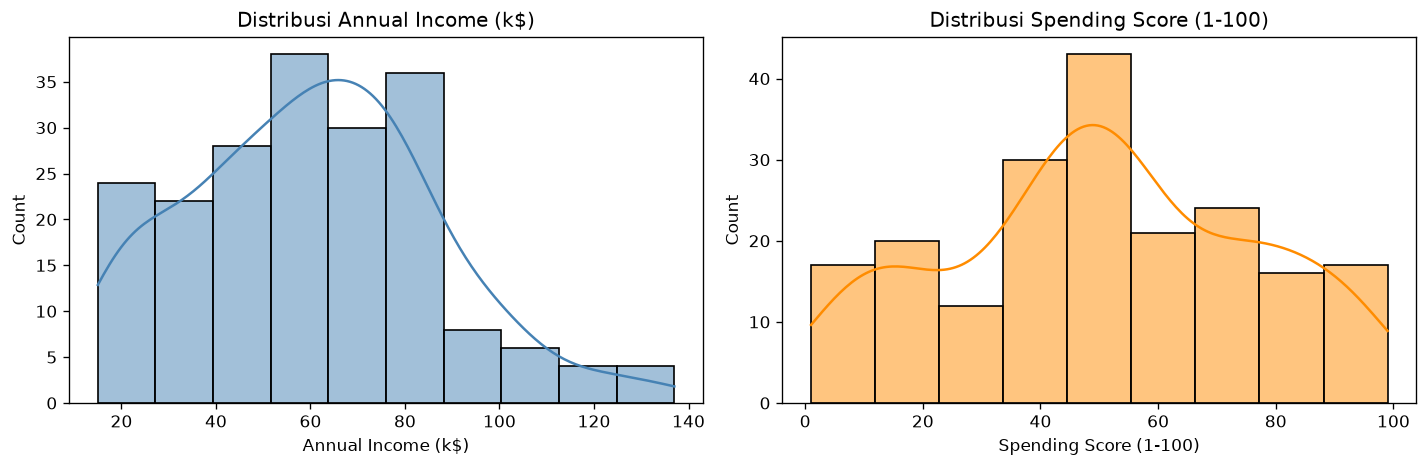

In [5]:
# Tampilkan distribusi Annual Income (k$) dan Spending Score (1-100)
# menggunakan histogram dan/atau boxplot.
# Amati rentang, bentuk distribusi, dan kemungkinan outlier.

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['Annual Income (k$)'], kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Distribusi Annual Income (k$)')
sns.histplot(df['Spending Score (1-100)'], kde=True, ax=axes[1], color='darkorange')
axes[1].set_title('Distribusi Spending Score (1-100)')
plt.tight_layout(); plt.show()
print(df[['Annual Income (k$)', 'Spending Score (1-100)']].describe().to_string())

<ipython-input-1-29cb446c01f8>:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.title('Annual Income vs Spending Score (tanpa label)'); plt.tight_layout(); plt.show()


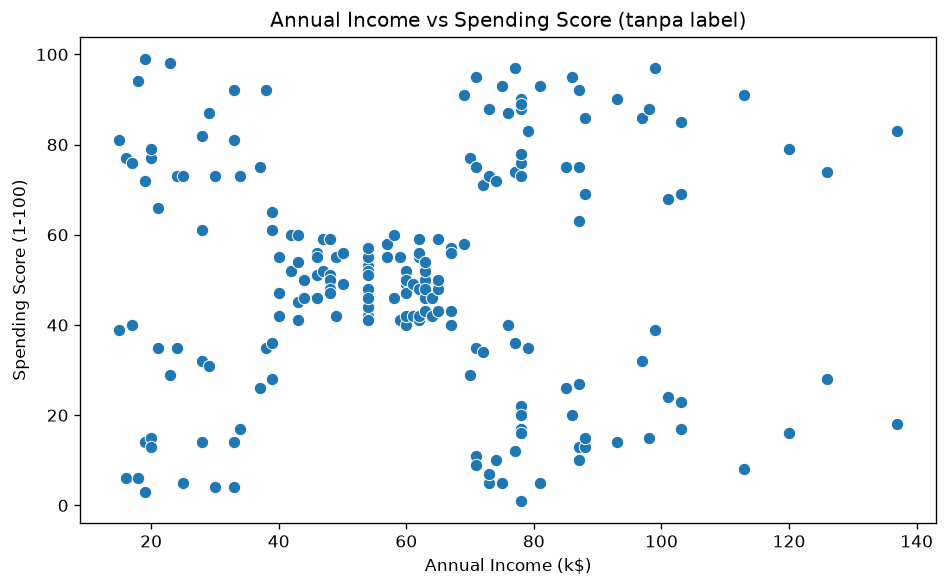

In [6]:
# Buat scatter plot dari Annual Income (k$) terhadap Spending Score (1-100).
# Jangan warnai berdasarkan label apa pun terlebih dahulu.
# Amati apakah terlihat kelompok-kelompok yang terpisah.

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Annual Income (k$)', y='Spending Score (1-100)', s=55)
plt.title('Annual Income vs Spending Score (tanpa label)'); plt.tight_layout(); plt.show()

## Pertanyaan EDA

Tuliskan pengamatan singkat:
- Apakah ada missing value atau baris duplikat?
- Bagaimana rentang pendapatan dan spending score?
- Apakah kedua fitur tampak memiliki kelompok yang terpisah?

Jawaban:

Data terdiri dari 200 pelanggan. Missing value dan baris duplikat tidak ditemukan. Pendapatan tahunan berada pada rentang 15 sampai 137 k$, dengan rata-rata 60,56 k$. Spending score berada pada rentang 1 sampai 99, dengan rata-rata 50,20.

Distribusi pendapatan sedikit menceng ke kanan karena ada beberapa pelanggan dengan pendapatan di atas 100 k$. Spending score lebih merata dan berpusat di sekitar 50. Scatter plot menunjukkan lima kelompok umum, yaitu pelanggan dengan pendapatan dan belanja rendah, pendapatan rendah dan belanja tinggi, kelompok menengah, pendapatan tinggi dan belanja rendah, serta pendapatan dan belanja tinggi. Batas antarkelompok terlihat, tetapi tidak semua titik terpisah dengan jelas.


# 2. Preprocessing

In [9]:
# Periksa dan tangani missing value serta baris duplikat jika ditemukan.
# Karena CustomerID adalah identitas, jangan masukkan kolom tersebut ke fitur clustering.
# Pilih dua fitur numerik:
#   Annual Income (k$)
#   Spending Score (1-100)
# Simpan dalam DataFrame X.

df = df.drop_duplicates().copy()
features = ['Annual Income (k$)', 'Spending Score (1-100)']
X = df[features].dropna().copy()
print('Baris setelah duplikat dibuang:', len(df))
print('Baris fitur valid:', len(X))
print('Missing value fitur:', X.isna().sum().to_dict())

Baris setelah duplikat dibuang: 200
Baris fitur valid: 200
Missing value fitur: {'Annual Income (k$)': 0, 'Spending Score (1-100)': 0}


In [10]:
# Lakukan feature scaling menggunakan StandardScaler.
# Simpan hasilnya sebagai X_scaled.
# Ubah hasil scaling menjadi DataFrame agar nama kolom tetap terlihat.
# Tampilkan beberapa baris X_scaled dan statistik deskriptifnya.

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=features, index=X.index)
print('Sampel hasil scaling:\n', X_scaled.head().to_string())
print('\nStatistik hasil scaling:\n', X_scaled.describe().to_string())

Sampel hasil scaling:
    Annual Income (k$)  Spending Score (1-100)
0           -1.738999               -0.434801
1           -1.738999                1.195704
2           -1.700830               -1.715913
3           -1.700830                1.040418
4           -1.662660               -0.395980

Statistik hasil scaling:
        Annual Income (k$)  Spending Score (1-100)
count        2.000000e+02            2.000000e+02
mean        -2.131628e-16           -1.465494e-16
std          1.002509e+00            1.002509e+00
min         -1.738999e+00           -1.910021e+00
25%         -7.275093e-01           -5.997931e-01
50%          3.587926e-02           -7.764312e-03
75%          6.656748e-01            8.851316e-01
max          2.917671e+00            1.894492e+00


Scaling menyamakan skala dan pusat kedua fitur sehingga jarak tidak didominasi rentang pendapatan.


<ipython-input-1-e2d500904bc4>:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


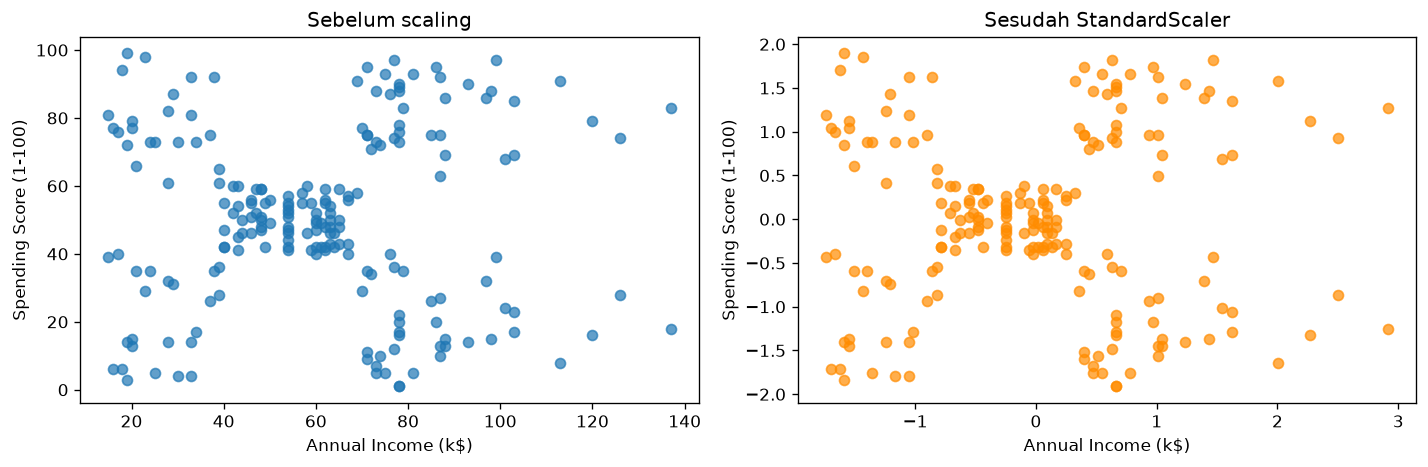

In [11]:
# Buat scatter plot sebelum dan sesudah scaling.
# Jelaskan mengapa scaling penting, terutama ketika algoritma menggunakan jarak
# atau mengasumsikan skala fitur yang sebanding.

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(X[features[0]], X[features[1]], alpha=.7); axes[0].set_title('Sebelum scaling')
axes[1].scatter(X_scaled[features[0]], X_scaled[features[1]], alpha=.7, color='darkorange'); axes[1].set_title('Sesudah StandardScaler')
for ax in axes: ax.set_xlabel(features[0]); ax.set_ylabel(features[1])
plt.tight_layout(); plt.show()
print('Scaling menyamakan skala dan pusat kedua fitur sehingga jarak tidak didominasi rentang pendapatan.')

**Fitur yang digunakan:** `Annual Income (k$)` dan `Spending Score (1-100)`.

Tuliskan alasan pemilihan kedua fitur tersebut dan jelaskan mengapa `CustomerID` tidak digunakan.

**Alasan pemilihan fitur:**

Annual Income dan Spending Score dipilih karena menunjukkan kemampuan belanja dan kebiasaan pelanggan dalam menggunakan uangnya. Kedua fitur ini juga mudah dibandingkan dalam scatter plot dan dapat membantu menjelaskan perbedaan segmen pelanggan. CustomerID tidak digunakan karena hanya berfungsi sebagai nomor identitas. Nilainya tidak menggambarkan karakteristik pelanggan, sehingga dapat membuat pola cluster yang tidak bermakna.


# 3. Eksperimen DBSCAN

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) membentuk cluster dari kumpulan titik yang padat. Titik yang tidak memenuhi kepadatan minimum dapat diberi label `-1`, yang berarti noise.

Parameter utama:
- `eps`: jarak maksimum agar dua titik dianggap berdekatan.
- `min_samples`: jumlah minimum titik di sekitar suatu titik agar titik tersebut dianggap sebagai titik inti (*core point*).

DBSCAN tidak perlu menentukan jumlah cluster di awal, tetapi hasilnya sensitif terhadap `eps` dan `min_samples`.

In [15]:
# Jalankan DBSCAN pada X_scaled.
# Mulai dengan eps dan min_samples yang masuk akal, misalnya eps=0.3 dan min_samples=5.
# Simpan label hasil clustering sebagai labels_dbscan.
# Catatan: nilai eps perlu dicoba dan dievaluasi, bukan dianggap pasti paling baik.

# Nilai awal sesuai lembar tugas; tabel eksperimen di bawah dipakai untuk menilai sensitivitas.
dbscan = DBSCAN(eps=0.3, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_scaled)
print('DBSCAN eps=0.3, min_samples=5')

DBSCAN eps=0.3, min_samples=5


In [16]:
# Tampilkan jumlah anggota setiap label hasil DBSCAN.
# Hitung jumlah cluster dengan tidak memasukkan label -1.
# Hitung juga jumlah titik noise (label -1).

counts_dbscan = pd.Series(labels_dbscan).value_counts().sort_index()
n_clusters_dbscan = len(set(labels_dbscan) - {-1})
n_noise_dbscan = int(np.sum(labels_dbscan == -1))
print('Jumlah anggota per label:\n', counts_dbscan.to_string())
print('Jumlah cluster:', n_clusters_dbscan, '| Noise:', n_noise_dbscan)

Jumlah anggota per label:
 -1    35
 0    12
 1     5
 2     7
 3    88
 4    30
 5    14
 6     9
Jumlah cluster: 7 | Noise: 35


<ipython-input-1-5cd026c99203>:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.title(f'DBSCAN: {n_clusters_dbscan} cluster, {n_noise_dbscan} noise'); plt.tight_layout(); plt.show()


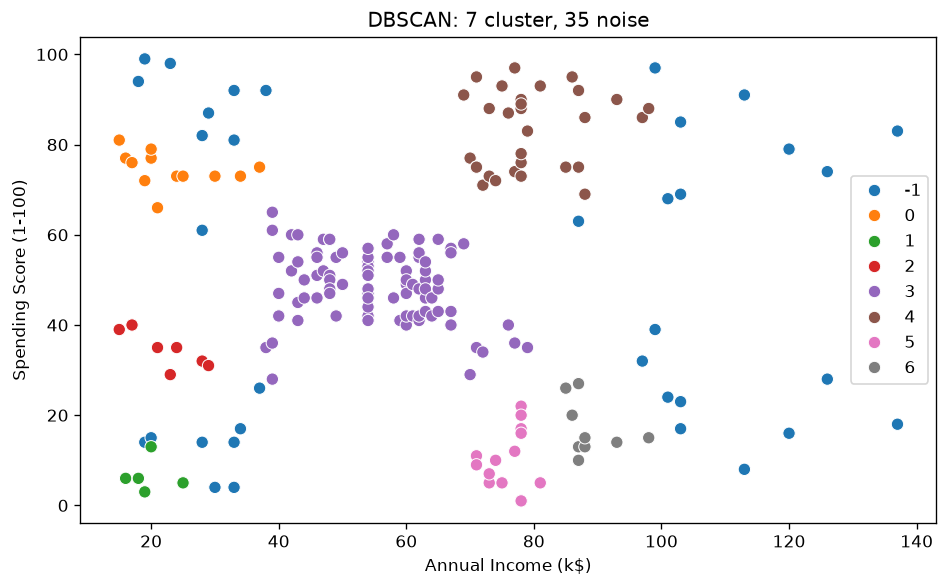

In [17]:
# Buat scatter plot hasil DBSCAN berdasarkan labels_dbscan.
# Gunakan X_scaled atau X untuk koordinat plot; untuk interpretasi, X (fitur asli)
# biasanya lebih mudah dipahami.
# Beri judul dan label sumbu yang jelas, serta pastikan noise dapat dibedakan.

plt.figure(figsize=(8, 5))
sns.scatterplot(x=X[features[0]], y=X[features[1]], hue=labels_dbscan, palette='tab10', s=55)
plt.title(f'DBSCAN: {n_clusters_dbscan} cluster, {n_noise_dbscan} noise'); plt.tight_layout(); plt.show()

In [18]:
# Coba beberapa kombinasi eps dan min_samples.
# Buat tabel ringkasan yang berisi eps, min_samples, jumlah cluster (tanpa noise),
# jumlah noise, dan Silhouette Score jika metrik tersebut valid.
# Hindari menghitung silhouette jika hasilnya hanya satu cluster atau semua titik noise.

rows=[]
for eps in [0.2, 0.25, 0.3, 0.35, 0.4, 0.5]:
 for min_samples in [3, 5, 8]:
  lab=DBSCAN(eps=eps,min_samples=min_samples).fit_predict(X_scaled)
  k=len(set(lab)-{-1}); noise=int(np.sum(lab==-1)); mask=lab!=-1
  sil=silhouette_score(X_scaled[mask],lab[mask]) if k>=2 and mask.sum()>k else np.nan
  rows.append({'eps':eps,'min_samples':min_samples,'jumlah_cluster':k,'noise':noise,'silhouette':sil})
dbscan_results=pd.DataFrame(rows)
print(dbscan_results.to_string(index=False, float_format=lambda x:f'{x:.4f}'))
# Pilih kandidat dengan silhouette valid tertinggi; bila tak ada, prioritaskan beberapa cluster dan noise lebih rendah.
valid=dbscan_results.dropna(subset=['silhouette'])
if len(valid):
 best_db=valid.sort_values(['silhouette','noise'],ascending=[False,True]).iloc[0]
else:
 best_db=dbscan_results.sort_values(['jumlah_cluster','noise'],ascending=[False,True]).iloc[0]
print('Kandidat DBSCAN untuk perbandingan:', best_db.to_dict())

   eps  min_samples  jumlah_cluster  noise  silhouette
0.2000            3              13     44      0.4697
0.2000            5               7     77      0.5856
0.2000            8               2    116      0.6027
0.2500            3              12     16      0.4090
0.2500            5               6     50      0.5317
0.2500            8               5     79      0.5947
0.3000            3               9     14      0.4720
0.3000            5               7     35      0.5243
0.3000            8               5     72      0.5926
0.3500            3               7     11      0.5154
0.3500            5               6     23      0.5577
0.3500            8               4     55      0.5994
0.4000            3               4     10      0.3954
0.4000            5               4     15      0.4781
0.4000            8               5     25      0.5490
0.5000            3               2      7      0.3892
0.5000            5               2      8      0.3876
0.5000    

### Analisis DBSCAN

- Apa pengaruh kenaikan `eps` terhadap jumlah cluster dan noise?
- Apa pengaruh `min_samples`?
- Apakah ada kombinasi parameter yang menghasilkan satu cluster besar atau terlalu banyak noise?



Pada hasil grid, kenaikan `eps` umumnya mengurangi jumlah cluster dan jumlah noise karena lebih banyak titik dianggap saling berdekatan. Dengan `min_samples=5`, `eps=0,2` menghasilkan 7 cluster dan 77 noise, sedangkan `eps=0,5` menghasilkan 2 cluster dan 8 noise. Kenaikan `min_samples` membuat syarat kepadatan lebih ketat. Pada `eps=0,3`, perubahan `min_samples` dari 3 menjadi 8 mengurangi cluster dari 9 menjadi 5 dan menaikkan noise dari 14 menjadi 72.

Grid notebook tidak menghasilkan satu cluster tunggal. Namun, kombinasi `eps=0,2` dan `min_samples=8` memberi 116 noise dari 200 pelanggan, sehingga terlalu banyak data tidak masuk ke cluster utama. Laporan yang dilampirkan mencatat hasil lain dengan `eps=0,38`, yaitu 5 cluster dan 13 noise. Hasil tersebut berasal dari konfigurasi berbeda dari grid yang tersimpan di notebook.


# 4. Eksperimen BIRCH

BIRCH (*Balanced Iterative Reducing and Clustering using Hierarchies*) membangun struktur pohon ringkasan cluster. Parameter `threshold` mengatur seberapa dekat titik harus berada agar dapat digabungkan dalam subcluster. `n_clusters` menentukan jumlah cluster akhir jika diberikan.

Berbeda dari DBSCAN, BIRCH tidak memberi label noise secara eksplisit.

In [22]:
# Latih model Birch pada X_scaled.
# Coba threshold awal, misalnya 0.5, dan n_clusters=5.
# Simpan label hasil clustering sebagai labels_birch.
# Catatan: jumlah cluster akhir dapat berubah sesuai parameter yang digunakan.

birch = Birch(threshold=0.5, n_clusters=5)
labels_birch = birch.fit_predict(X_scaled)
print('BIRCH threshold=0.5, n_clusters=5')

BIRCH threshold=0.5, n_clusters=5


In [23]:
# Tampilkan jumlah anggota setiap cluster BIRCH.
# Tampilkan juga jumlah cluster yang terbentuk.

counts_birch=pd.Series(labels_birch).value_counts().sort_index()
print('Jumlah anggota per cluster:\n',counts_birch.to_string())
print('Jumlah cluster:',len(np.unique(labels_birch)))

Jumlah anggota per cluster:
 0     36
1    109
2      8
3     25
4     22
Jumlah cluster: 5


<ipython-input-1-f709736d5879>:5: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.title(f'BIRCH: {len(np.unique(labels_birch))} cluster'); plt.tight_layout(); plt.show()


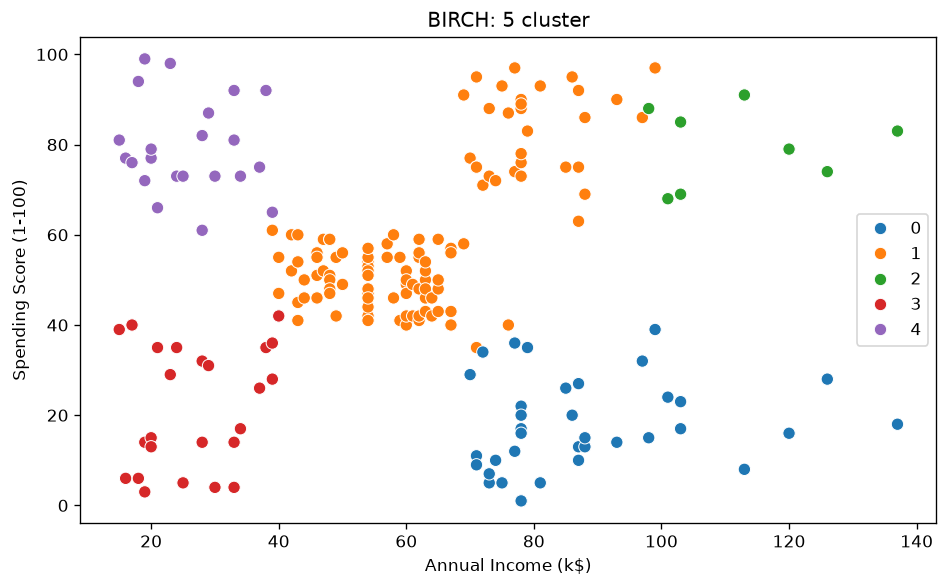

In [24]:
# Buat scatter plot hasil BIRCH pada ruang fitur asli X.
# Warnai titik berdasarkan labels_birch.

plt.figure(figsize=(8,5))
sns.scatterplot(x=X[features[0]],y=X[features[1]],hue=labels_birch,palette='tab10',s=55)
plt.title(f'BIRCH: {len(np.unique(labels_birch))} cluster'); plt.tight_layout(); plt.show()

In [25]:
# Bandingkan beberapa nilai threshold (misalnya 0.3, 0.5, 0.7, 1.0)
# dengan jumlah cluster akhir yang sama jika memungkinkan.
# Buat tabel berisi threshold, jumlah cluster, dan Silhouette Score bila valid.

rows=[]
for threshold in [0.3,0.5,0.7,1.0]:
 lab=Birch(threshold=threshold,n_clusters=5).fit_predict(X_scaled)
 k=len(np.unique(lab)); sil=silhouette_score(X_scaled,lab) if 2<=k<len(lab) else np.nan
 rows.append({'threshold':threshold,'jumlah_cluster':k,'silhouette':sil})
birch_results=pd.DataFrame(rows)
print(birch_results.to_string(index=False,float_format=lambda x:f'{x:.4f}'))


 threshold  jumlah_cluster  silhouette
    0.3000               5      0.4781
    0.5000               5      0.4145
    0.7000               5      0.4207
    1.0000               4      0.3886


/media/dff/Elements1/ITS_semester3/ML/Praktikum/.venv/lib/python3.12/site-packages/sklearn/cluster/_birch.py:711: ConvergenceWarning: Number of subclusters found (4) by BIRCH is less than (5). Decrease the threshold.
  warnings.warn(


### Analisis BIRCH

- Apa yang terjadi pada jumlah cluster ketika `threshold` diperbesar?
- Apa perbedaan BIRCH dan DBSCAN dalam menangani titik yang berada jauh dari kelompok utama?
- Apakah hasil BIRCH berubah ketika `n_clusters` ditentukan?


Dengan `n_clusters=5`, threshold 0,3, 0,5, dan 0,7 menghasilkan lima cluster. Saat threshold dinaikkan menjadi 1,0, hasilnya menjadi empat cluster karena BIRCH hanya membentuk empat subcluster. Threshold yang lebih besar membuat titik lebih mudah digabungkan ke subcluster yang sama. Parameter `n_clusters` mengatur jumlah cluster akhir jika jumlah subcluster yang terbentuk mencukupi.

BIRCH tidak memberi label noise secara khusus. Titik yang jauh dari kelompok utama tetap dimasukkan ke salah satu cluster. DBSCAN dapat memberi label `-1` pada titik yang tidak memenuhi syarat kepadatan.


# 5. Eksperimen EM dengan Gaussian Mixture Model

Expectation-Maximization (EM) adalah algoritma iteratif untuk mengestimasi parameter model probabilistik. Dalam praktikum ini, EM digunakan untuk melatih **Gaussian Mixture Model (GMM)**.

GMM menganggap data berasal dari campuran beberapa distribusi Gaussian. Untuk setiap titik, GMM menghasilkan probabilitas keanggotaan pada setiap komponen, kemudian label cluster ditentukan dari komponen dengan probabilitas terbesar.

Parameter utama:
- `n_components`: jumlah distribusi Gaussian/cluster yang dimodelkan.
- `covariance_type`: bentuk matriks kovarians yang digunakan.
- `random_state`: agar hasil eksperimen dapat diulang.

In [29]:
# Latih GaussianMixture pada X_scaled menggunakan EM.
# Mulai dengan n_components=5, covariance_type='full', dan random_state=42.
# Simpan label hasil prediksi sebagai labels_gmm.

gmm=GaussianMixture(n_components=5,covariance_type='full',random_state=SEED)
labels_gmm=gmm.fit_predict(X_scaled)
print('GMM n_components=5, covariance_type=full, random_state=42')

GMM n_components=5, covariance_type=full, random_state=42


In [30]:
# Tampilkan jumlah anggota setiap cluster GMM.
# Gunakan predict_proba untuk melihat probabilitas keanggotaan tiap titik.
# Tampilkan beberapa baris probabilitas dan periksa apakah ada titik dengan
# keanggotaan yang relatif tidak pasti.

counts_gmm=pd.Series(labels_gmm).value_counts().sort_index()
proba=gmm.predict_proba(X_scaled)
print('Jumlah anggota per cluster:\n',counts_gmm.to_string())
print('Probabilitas keanggotaan (10 baris):\n',pd.DataFrame(proba,columns=[f'komponen_{i}' for i in range(gmm.n_components)]).head(10).round(4).to_string(index=False))
uncertain=np.argsort(proba.max(axis=1))[:5]
print('5 titik dengan keanggotaan paling tidak pasti (indeks, probabilitas maksimum):',[(X.index[i],round(float(proba[i].max()),4)) for i in uncertain])

Jumlah anggota per cluster:
 0    84
1    39
2    21
3    33
4    23
Probabilitas keanggotaan (10 baris):
  komponen_0  komponen_1  komponen_2  komponen_3  komponen_4
     0.0000      0.0000      0.0010      0.0000      0.9990
     0.0000      0.0002      0.9998      0.0000      0.0000
     0.0000      0.0000      0.0000      0.0002      0.9998
     0.0001      0.0002      0.9997      0.0000      0.0000
     0.0001      0.0000      0.0016      0.0000      0.9984
     0.0002      0.0002      0.9996      0.0000      0.0000
     0.0000      0.0000      0.0000      0.0003      0.9997
     0.0000      0.0003      0.9997      0.0000      0.0000
     0.0000      0.0000      0.0000      0.0004      0.9996
     0.0012      0.0002      0.9984      0.0000      0.0002
5 titik dengan keanggotaan paling tidak pasti (indeks, probabilitas maksimum): [(124, 0.5029), (48, 0.6114), (49, 0.6114), (27, 0.6746), (160, 0.7721)]


<ipython-input-1-a6fbfa3330ba>:5: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.title(f'GMM: {len(np.unique(labels_gmm))} komponen'); plt.tight_layout(); plt.show()


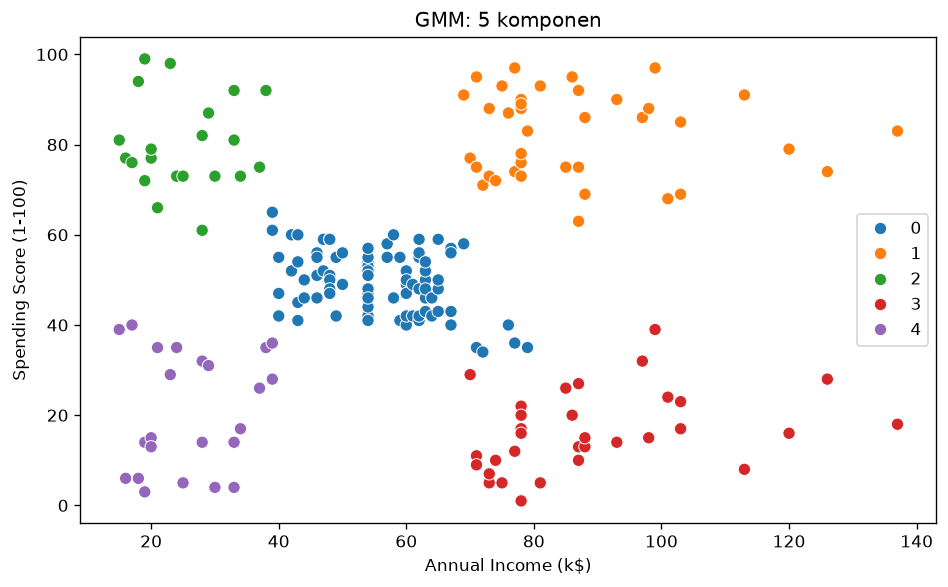

In [31]:
# Buat scatter plot hasil GMM pada ruang fitur asli X.
# Warnai titik berdasarkan labels_gmm.

plt.figure(figsize=(8,5))
sns.scatterplot(x=X[features[0]],y=X[features[1]],hue=labels_gmm,palette='tab10',s=55)
plt.title(f'GMM: {len(np.unique(labels_gmm))} komponen'); plt.tight_layout(); plt.show()

In [32]:
# Bandingkan beberapa nilai n_components (misalnya 2 sampai 8).
# Catat Silhouette Score dan BIC untuk setiap model.
# BIC yang lebih rendah menunjukkan keseimbangan model dan kecocokan data yang lebih baik
# menurut kriteria BIC, tetapi tetap perlu dipertimbangkan bersama visualisasi dan konteks.

rows=[]
for k in range(2,9):
 model=GaussianMixture(n_components=k,covariance_type='full',random_state=SEED).fit(X_scaled)
 lab=model.predict(X_scaled)
 sil=silhouette_score(X_scaled,lab) if 2<=len(np.unique(lab))<len(lab) else np.nan
 rows.append({'n_components':k,'silhouette':sil,'BIC':model.bic(X_scaled)})
gmm_results=pd.DataFrame(rows)
print(gmm_results.to_string(index=False,float_format=lambda x:f'{x:.4f}'))
best_gmm_row=gmm_results.sort_values('BIC').iloc[0]
print('n_components dengan BIC terendah:',int(best_gmm_row.n_components))

 n_components  silhouette       BIC
            2      0.3791 1153.9047
            3      0.4302 1151.7183
            4      0.4134 1103.7901
            5      0.5537 1058.6523
            6      0.5170 1074.6828
            7      0.5091 1087.3285
            8      0.4302 1102.3707
n_components dengan BIC terendah: 5


### Analisis EM/GMM

- Apa arti probabilitas keanggotaan yang dihasilkan GMM?
- Apa yang terjadi ketika `n_components` diubah?
- Mengapa jumlah cluster GMM perlu ditentukan sebelum model dilatih?
- Apakah model dengan Silhouette Score tertinggi juga memiliki BIC terendah?


Probabilitas keanggotaan menunjukkan seberapa besar kemungkinan seorang pelanggan termasuk ke setiap komponen Gaussian. Pada tahap E, EM memperkirakan probabilitas keanggotaan tersebut. Pada tahap M, EM memperbarui parameter komponen berdasarkan perkiraan itu. Kedua tahap diulang sampai model mencapai hasil yang stabil.

Nilai `n_components` menentukan jumlah distribusi yang akan dipelajari GMM. Pada hasil notebook, lima komponen menghasilkan silhouette tertinggi, yaitu 0,5537, dan BIC terendah, yaitu 1058,6523. Jumlah komponen harus ditentukan sebelum model dilatih. Kita dapat membandingkan beberapa nilai terlebih dahulu dengan melihat metrik dan kemudahan interpretasi hasilnya.


# 6. Evaluasi dan Perbandingan Model

Bandingkan model DBSCAN, BIRCH, dan GMM menggunakan:
- Jumlah cluster yang terbentuk.
- Jumlah titik noise, khusus untuk DBSCAN.
- Silhouette Score: semakin tinggi biasanya semakin baik.
- Davies-Bouldin Index: semakin rendah biasanya semakin baik.
- Calinski-Harabasz Score: semakin tinggi biasanya semakin baik.

Metrik internal perlu ditafsirkan dengan hati-hati. Untuk DBSCAN, keluarkan titik noise dari perhitungan metrik jika ingin menilai kualitas cluster yang terbentuk. Metrik tidak dapat dihitung secara bermakna jika hasilnya hanya satu cluster atau setiap titik menjadi cluster sendiri.

In [36]:
# Buat fungsi evaluasi yang menerima X_scaled dan label clustering.
# Untuk DBSCAN, hitung metrik pada titik non-noise saja.
# Pastikan metrik hanya dihitung jika terdapat setidaknya 2 cluster
# dan jumlah cluster lebih kecil daripada jumlah titik yang dievaluasi.

def evaluate_clustering(X_values, labels, exclude_noise=False):
 labels=np.asarray(labels); mask=labels!=-1 if exclude_noise else np.ones(len(labels),dtype=bool)
 x=np.asarray(X_values)[mask]; y=labels[mask]; k=len(np.unique(y))
 result={'jumlah_cluster':k,'jumlah_noise':int(np.sum(labels==-1)) if exclude_noise else 0,'silhouette':np.nan,'davies_bouldin':np.nan,'calinski_harabasz':np.nan}
 if 2<=k<len(y):
  result.update(silhouette=silhouette_score(x,y),davies_bouldin=davies_bouldin_score(x,y),calinski_harabasz=calinski_harabasz_score(x,y))
 return result


In [37]:
# Evaluasi hasil terbaik dari DBSCAN, BIRCH, dan GMM.
# Sajikan ringkasan dalam satu DataFrame/tabel:
# model, jumlah cluster, jumlah noise, silhouette, Davies-Bouldin, Calinski-Harabasz.
# Untuk BIRCH dan GMM, jumlah noise dapat ditulis 0 atau N/A karena algoritma
# tersebut tidak menandai noise secara eksplisit.

# DBSCAN memakai kandidat parameter dengan silhouette valid terbaik; evaluasi BIRCH/GMM memakai hasil baseline.
labels_dbscan_best=DBSCAN(eps=float(best_db.eps),min_samples=int(best_db.min_samples)).fit_predict(X_scaled)
summary=[]
for name,lab,is_db in [('DBSCAN',labels_dbscan_best,True),('BIRCH',labels_birch,False),('EM/GMM',labels_gmm,False)]:
 r=evaluate_clustering(X_scaled,lab,exclude_noise=is_db); r['model']=name; summary.append(r)
comparison=pd.DataFrame(summary)[['model','jumlah_cluster','jumlah_noise','silhouette','davies_bouldin','calinski_harabasz']]
print('Parameter DBSCAN terpilih:',{'eps':float(best_db.eps),'min_samples':int(best_db.min_samples)})
print(comparison.to_string(index=False,float_format=lambda x:f'{x:.4f}'))

Parameter DBSCAN terpilih: {'eps': 0.2, 'min_samples': 8}
 model  jumlah_cluster  jumlah_noise  silhouette  davies_bouldin  calinski_harabasz
DBSCAN               2           116      0.6027          0.4058            71.0668
 BIRCH               5             0      0.4145          0.6979           125.9486
EM/GMM               5             0      0.5537          0.5760           244.9402


<ipython-input-1-922288735720>:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


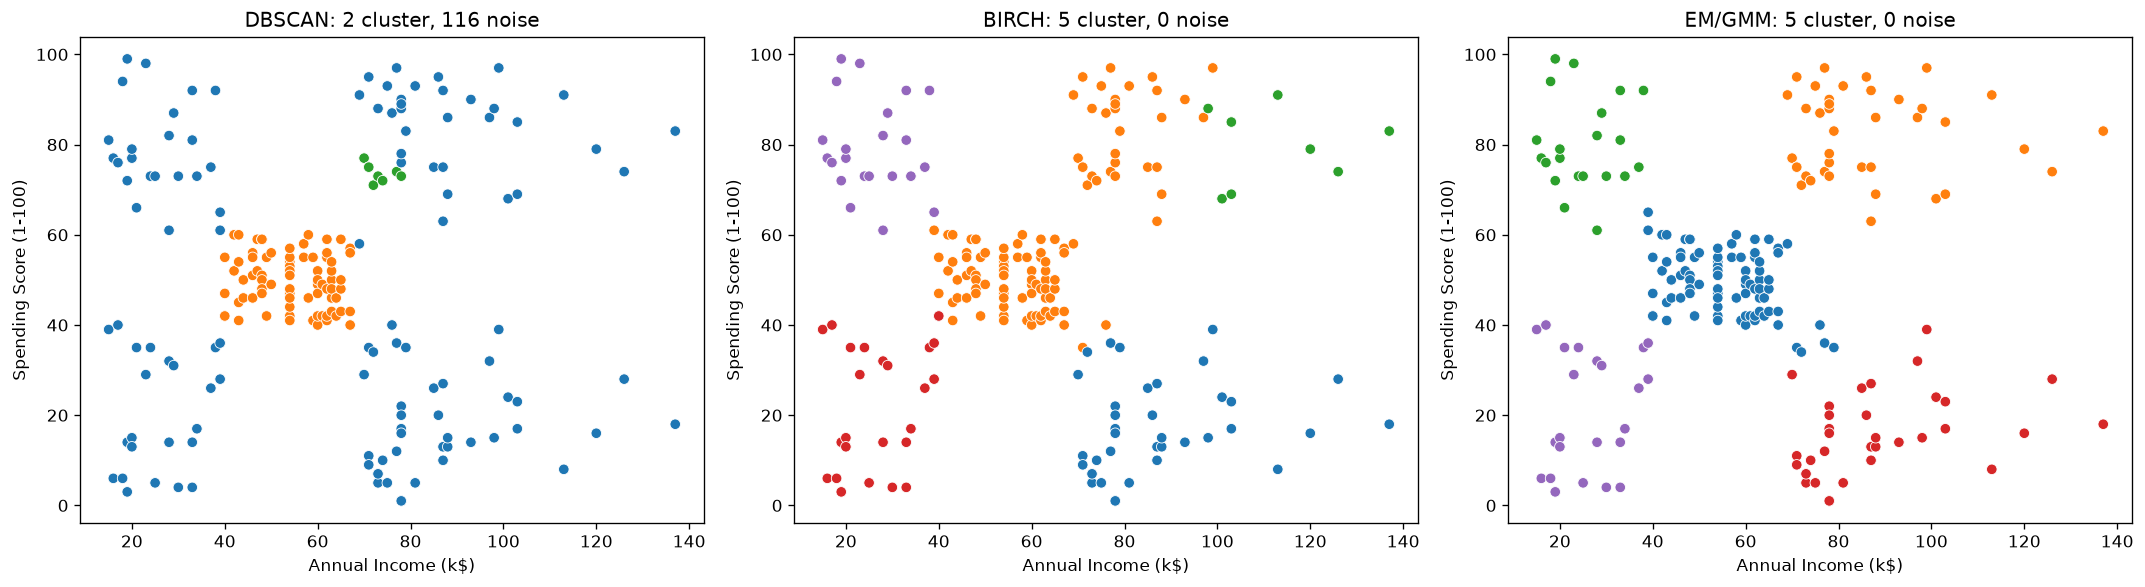

In [38]:
# Buat tiga scatter plot dalam satu baris subplot:
# DBSCAN, BIRCH, dan GMM.
# Gunakan koordinat dari fitur asli X dan warna berdasarkan label cluster.
# Beri judul yang menunjukkan algoritma dan jumlah cluster/noise.

fig,axes=plt.subplots(1,3,figsize=(18,5))
for ax,(name,lab) in zip(axes,[('DBSCAN',labels_dbscan_best),('BIRCH',labels_birch),('EM/GMM',labels_gmm)]):
 sns.scatterplot(x=X[features[0]],y=X[features[1]],hue=lab,palette='tab10',s=40,legend=False,ax=ax)
 k=len(set(lab)-{-1}); noise=int(np.sum(np.asarray(lab)==-1))
 ax.set_title(f'{name}: {k} cluster, {noise} noise'); ax.set_xlabel(features[0]); ax.set_ylabel(features[1])
plt.tight_layout(); plt.show()

In [39]:
# Buat profil cluster pada fitur asli.
# Untuk setiap algoritma, tampilkan jumlah anggota serta median dan rata-rata
# Annual Income (k$) dan Spending Score (1-100) untuk setiap cluster.
# Untuk DBSCAN, analisis label -1 (noise) secara terpisah.

for name,lab in [('DBSCAN',labels_dbscan_best),('BIRCH',labels_birch),('EM/GMM',labels_gmm)]:
 profile=X.assign(cluster=np.asarray(lab)).groupby('cluster').agg(jumlah=('cluster','size'),income_median=(features[0],'median'),income_mean=(features[0],'mean'),spending_median=(features[1],'median'),spending_mean=(features[1],'mean')).round(2)
 print('\n',name,'(label -1 adalah noise bila ada):\n',profile.to_string())


 DBSCAN (label -1 adalah noise bila ada):
          jumlah  income_median  income_mean  spending_median  spending_mean
cluster                                                                    
-1          116           74.5        63.57             39.0          48.85
 0           76           54.0        54.63             50.0          49.78
 1            8           72.5        73.25             73.5          73.75

 BIRCH (label -1 adalah noise bila ada):
          jumlah  income_median  income_mean  spending_median  spending_mean
cluster                                                                    
0            36           83.0        87.75             16.0          17.58
1           109           62.0        62.39             55.0          59.26
2             8          108.0       112.62             81.0          79.62
3            25           28.0        27.40             26.0          22.60
4            22           24.5        25.73             77.0          79.36



### Ringkasan Perbandingan

Lengkapi tabel atau tuliskan rangkuman berdasarkan hasil eksperimen:

| Aspek | DBSCAN | BIRCH | EM/GMM |
|---|---|---|---|
| Perlu menentukan jumlah cluster di awal? | Tidak | Dapat ditentukan lewat `n_clusters`, tidak wajib jika memakai default | Ya, `n_components` harus ditetapkan |
| Dapat memberi label noise secara eksplisit? | Ya, label `-1` | Tidak | Tidak |
| Parameter yang paling memengaruhi hasil | `eps`, `min_samples` | `threshold`, `n_clusters` | `n_components`, `covariance_type`, inisialisasi |
| Bentuk cluster yang dapat dimodelkan | Bentuk kepadatan beragam, tetapi sensitif pada variasi kepadatan | Subcluster berbasis CF Tree lalu pengelompokan akhir | Gaussian/elips sesuai kovarians |
| Kelebihan | Tidak perlu jumlah cluster awal, dapat mendeteksi noise | Efisien merangkum data dan dapat diarahkan ke jumlah cluster | Keanggotaan probabilistik dan bentuk Gaussian fleksibel |
| Kekurangan | Sensitif pada parameter, kandidat grid menandai 116 dari 200 titik sebagai noise | Tidak punya noise eksplisit, jumlah target bisa tidak tercapai | Harus menentukan komponen, sensitif pada asumsi Gaussian dan inisialisasi |


DBSCAN tidak memerlukan jumlah cluster di awal dan dapat menandai noise. Hasilnya sangat dipengaruhi oleh `eps` dan `min_samples`. DBSCAN dapat menemukan cluster dengan bentuk beragam, tetapi sensitif jika kepadatan antarkelompok berbeda. BIRCH dipengaruhi oleh `threshold` dan `n_clusters`. Metode ini merangkum data melalui CF Tree dan tidak memberi label noise secara khusus. GMM memerlukan jumlah komponen sebelum model dilatih. Hasilnya dipengaruhi oleh `n_components`, jenis kovarians, dan inisialisasi. GMM memberikan probabilitas keanggotaan dan cocok untuk kelompok yang menyerupai sebaran Gaussian.



# 7. Analisis

Jelaskan hasil eksperimen dengan merujuk pada output notebook kalian sendiri. Bahas poin-poin berikut:

1. Mengapa fitur perlu di-scaling sebelum clustering?
2. Bagaimana perubahan parameter DBSCAN memengaruhi jumlah cluster dan noise?
3. Bagaimana parameter `threshold` dan `n_clusters` memengaruhi BIRCH?
4. Apa makna probabilitas keanggotaan GMM dan bagaimana EM menggunakannya?
5. Model mana yang paling mudah diinterpretasikan pada dataset ini? Jelaskan alasannya.
6. Apakah metrik evaluasi menunjukkan algoritma terbaik yang sama? Jika berbeda, apa kemungkinan penyebabnya?
7. Jelaskan karakteristik cluster berdasarkan median pendapatan dan spending score. Berikan nama deskriptif pada cluster jika memungkinkan.
8. Apa keterbatasan penggunaan hanya dua fitur dan dataset pelanggan yang berukuran kecil?

### Jawaban 

Scaling diperlukan karena pendapatan tahunan dan spending score memiliki rentang yang berbeda. Tanpa scaling, pendapatan dapat terlalu memengaruhi perhitungan jarak pada DBSCAN dan BIRCH. Scaling juga membantu GMM membandingkan kedua fitur dalam skala yang seimbang.

Pada grid DBSCAN, kenaikan `eps` umumnya mengurangi jumlah cluster dan noise. Dengan `min_samples=5`, perubahan `eps` dari 0,2 ke 0,5 mengubah hasil dari 7 cluster dan 77 noise menjadi 2 cluster dan 8 noise. Kenaikan `min_samples` memperketat syarat kepadatan. Pada `eps=0,3`, kenaikan `min_samples` dari 3 menjadi 8 mengurangi jumlah cluster dari 9 menjadi 5 dan menaikkan noise dari 14 menjadi 72. Tidak ada kombinasi di grid yang menghasilkan satu cluster tunggal. Kombinasi `eps=0,2` dan `min_samples=8` menghasilkan 116 noise, sedangkan laporan yang dilampirkan mencatat 5 cluster dan 13 noise untuk `eps=0,38`. Kedua hasil tersebut berasal dari konfigurasi yang berbeda.

Pada BIRCH dengan `n_clusters=5`, threshold 0,3, 0,5, dan 0,7 menghasilkan lima cluster. Threshold 1,0 menghasilkan empat cluster karena hanya empat subcluster yang terbentuk. Threshold yang lebih besar cenderung menggabungkan titik ke kelompok yang lebih besar. `n_clusters` mengatur jumlah cluster akhir jika jumlah subcluster yang terbentuk mencukupi. BIRCH tetap memasukkan titik yang jauh ke salah satu cluster, sedangkan DBSCAN dapat menandainya sebagai noise.

Probabilitas GMM menunjukkan kemungkinan pelanggan berasal dari masing-masing komponen Gaussian. EM memperkirakan probabilitas itu, lalu memperbarui parameter Gaussian secara berulang. Nilai `n_components` menentukan jumlah komponen yang dipelajari. Dalam hasil notebook, lima komponen memberi silhouette tertinggi sebesar 0,5537 dan BIC terendah sebesar 1058,6523. Karena jumlah komponen harus dipilih sebelum pelatihan, beberapa nilai perlu dibandingkan terlebih dahulu.

GMM paling mudah digunakan untuk menjelaskan lima segmen pelanggan karena model ini memberikan probabilitas keanggotaan dan profil median yang mudah dibaca. DBSCAN berguna untuk menemukan noise, tetapi kandidat terbaik menurut silhouette pada grid menandai 116 dari 200 pelanggan sebagai noise. Untuk metrik, output notebook menunjukkan DBSCAN memiliki silhouette 0,6027 dan Davies-Bouldin 0,4058, sedangkan GMM memiliki Calinski-Harabasz tertinggi sebesar 244,94. BIRCH memiliki silhouette 0,4145. Metrik DBSCAN dihitung hanya dari 84 pelanggan non-noise, sehingga perbandingannya tidak sepenuhnya sama dengan model lain. Angka pada laporan terlampir juga berbeda karena menggunakan konfigurasi dan hasil eksperimen yang berbeda.

Profil median GMM menunjukkan lima kelompok. Cluster 0 memiliki pendapatan dan spending menengah, dengan median 55,5 k$ dan 49,5. Cluster 1 memiliki pendapatan dan spending tinggi, dengan median 79 k$ dan 83. Cluster 2 memiliki pendapatan rendah dan spending tinggi, dengan median 24 k$ dan 77. Cluster 3 memiliki pendapatan tinggi dan spending rendah, dengan median 86 k$ dan 15. Cluster 4 memiliki pendapatan dan spending rendah, dengan median 25 k$ dan 17. Nomor cluster hanya label, jadi nama segmen ditentukan dari nilai median tersebut. Noise DBSCAN dibahas terpisah dan tidak otomatis berarti pelanggan anomali.

Analisis ini hanya memakai pendapatan dan spending score. Fitur lain seperti usia, gender, frekuensi transaksi, kategori produk, dan perubahan perilaku belum diperhitungkan. Dataset berisi 200 pelanggan, sehingga hasil dapat berubah karena parameter atau sampel yang digunakan dan belum tentu mewakili semua pelanggan. Hasilnya sebaiknya dibandingkan dengan data tambahan dan kebutuhan bisnis.


# 8. Kesimpulan dan Saran

Tuliskan kesimpulan berdasarkan eksperimen:
- Algoritma mana yang memberikan hasil paling berguna untuk dataset ini?
- Parameter apa yang dipilih dan mengapa?
- Apa perbedaan utama DBSCAN, BIRCH, dan EM/GMM yang kalian pelajari?
- Eksperimen lanjutan apa yang dapat dilakukan?

Pastikan kesimpulan didasarkan pada hasil eksperimen sendiri, bukan hanya teori.

### Kesimpulan dan Saran

GMM paling berguna sebagai segmentasi utama pada hasil notebook karena membentuk lima kelompok yang dapat dijelaskan dari profil median. Silhouette GMM adalah 0,5537 dan BIC terendah pada pengujian juga diperoleh dengan lima komponen. DBSCAN tetap bermanfaat untuk mendeteksi noise, tetapi konfigurasi grid dengan silhouette tertinggi menandai 116 pelanggan sebagai noise sehingga kurang cocok untuk membagi seluruh pelanggan.

Konfigurasi yang dibandingkan adalah DBSCAN dengan `eps=0,3` dan `min_samples=5` sebagai baseline, serta kandidat grid `eps=0,2` dan `min_samples=8`. BIRCH memakai `threshold=0,5` dan `n_clusters=5`. GMM memakai `n_components=5`, `covariance_type='full'`, dan `random_state=42`. Lima komponen dipilih karena menghasilkan silhouette tertinggi dan BIC terendah pada pengujian GMM. Hasil DBSCAN perlu dipertimbangkan bersama jumlah noise yang besar.

DBSCAN membentuk kelompok berdasarkan kepadatan dan dapat menandai noise tanpa menentukan jumlah cluster di awal. BIRCH merangkum data ke dalam CF Tree dan dapat diarahkan ke jumlah cluster tertentu, tetapi tidak memberi label noise. GMM memodelkan data sebagai campuran distribusi Gaussian dan memberi probabilitas keanggotaan, tetapi jumlah komponennya harus ditentukan sebelum pelatihan. Untuk pengembangan berikutnya, parameter ketiga metode dapat dibandingkan dengan proses tuning yang sama. Analisis juga dapat diperluas dengan fitur pelanggan lain, pengujian pada beberapa sampel, dan validasi apakah strategi pemasaran tiap segmen meningkatkan respons atau penjualan.


## Referensi

- Dataset: [Mall Customer Segmentation Data, Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data)
- Dokumentasi DBSCAN: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- Dokumentasi BIRCH: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.Birch.html)
- Dokumentasi Gaussian Mixture: [scikit-learn](https://scikit-learn.org/stable/modules/mixture.html#gaussian-mixture)